# Kesit İstatistik — Robust ve parametrik olmayan yöntemler

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## Mann–Whitney ve Wilcoxon

Bağımsız vardiya ile aynı kişilerin değişimi neden farklı test ister?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Eşleştirilmiş çizgilerin yönüyle grup histogramını ayır.

**Yorum sınırı:** Wilcoxon sıfır fark ve simetri koşulları; Mann–Whitney dağılımsal hedefi korunmalı.

**Alıştırma:** Sonra sütununu rastgele karıştır; eşleştirmenin etkisini açıklayarak iki testi yeniden çalıştır.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'Wilcoxon_esli': np.float64(6.146728992462158e-08), 'Mann_Whitney_bagimsiz': np.float64(0.10696593230130519)}


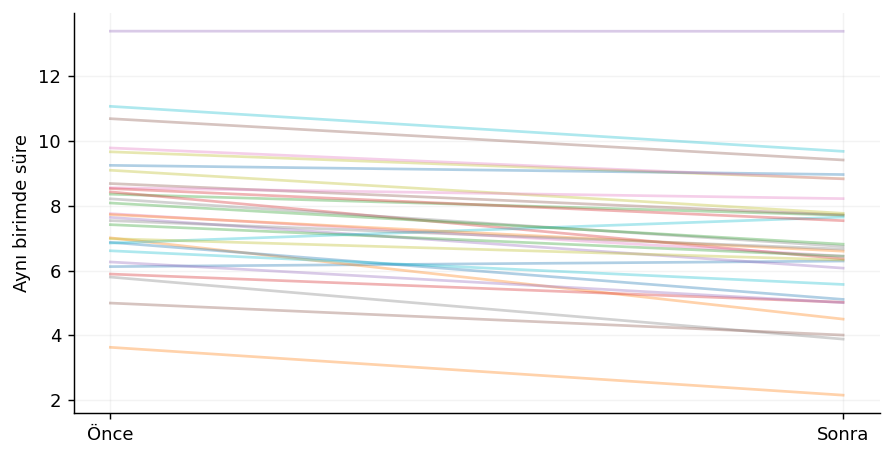

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

a=rng.lognormal(2,.35,30);b=a-rng.normal(.8,.6,30);ind=rng.lognormal(2,.35,35)
print({'Wilcoxon_esli':stats.wilcoxon(a,b).pvalue,'Mann_Whitney_bagimsiz':stats.mannwhitneyu(a,ind,method='asymptotic').pvalue})
plt.plot([0,1],np.vstack([a,b]),alpha=.35);plt.xticks([0,1],['Önce','Sonra']);plt.ylabel('Aynı birimde süre')

## Kruskal–Wallis ve Friedman

Üç bağımsız grup ile üç tekrarlı ölçümü nasıl ayırırım?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Aynı birimin üç ölçümü arasındaki bağı koru.

**Yorum sınırı:** Kruskal ve Friedman aynı deney tasarımını test etmez; genel p hangi çiftin farklı olduğunu söylemez.

**Alıştırma:** Birimin ortak etkisini artır; Friedman ile bağımsız yaklaşımın farkını açıkla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'Friedman_tekrarli': np.float64(0.00016995106759902634), 'Kruskal_bagimsiz_ornek': np.float64(0.00012229251283106288)}


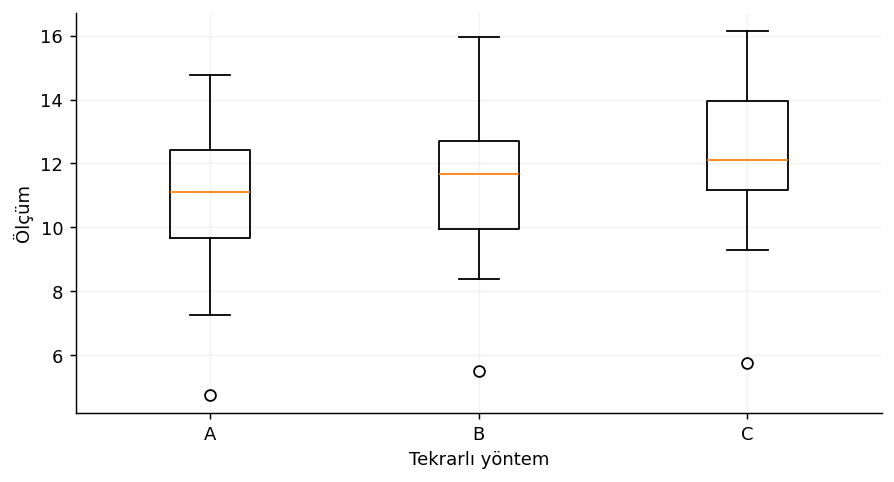

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

base=rng.normal(10,3,25);a=base+rng.normal(0,1,25);b=base+1+rng.normal(0,1,25);c=base+2+rng.normal(0,1,25)
print({'Friedman_tekrarli':stats.friedmanchisquare(a,b,c).pvalue,'Kruskal_bagimsiz_ornek':stats.kruskal(rng.normal(10,2,25),rng.normal(11,2,25),rng.normal(12,2,25)).pvalue})
plt.boxplot([a,b,c],tick_labels=['A','B','C']);plt.ylabel('Ölçüm');plt.xlabel('Tekrarlı yöntem')

## Robust özetler ve kırpılmış ortalama

Uç süreyi silmeden tipik performansı nasıl raporlarım?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Ortalama, medyan ve kırpılmış ortalamanın aykırılığa tepkisini karşılaştır.

**Yorum sınırı:** Kırpma önceden belirlenmeli; geçerli kuyruk maliyetini ortadan kaldırdığı varsayılmamalı.

**Alıştırma:** Son 80 dakikalık kaydı 800 yap; her özetin değişimini yaz.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'ortalama': np.float64(12.035374365028673), 'medyan': np.float64(10.291925442802448), 'kirpilmis': np.float64(10.314288079351364), 'MAD_normal_olcek': np.float64(0.7555055715297753)}


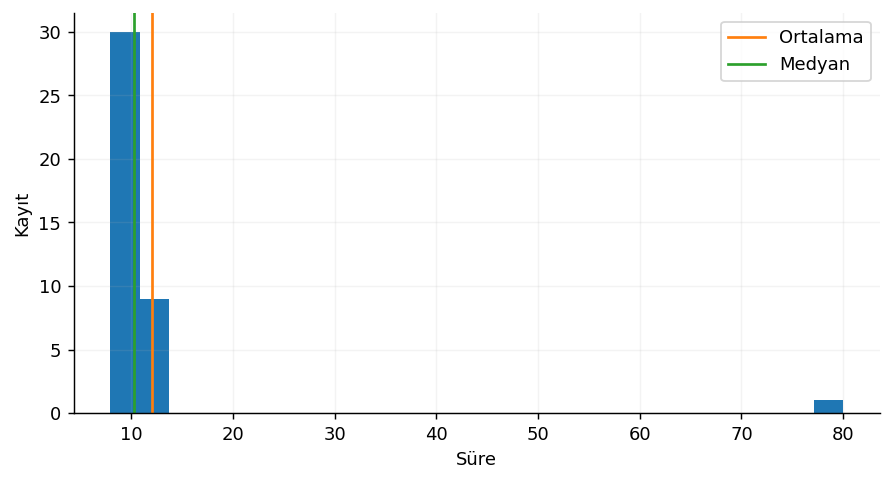

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

x=np.r_[rng.normal(10,1,39),80];trim=.1;med=np.median(x);mad=stats.median_abs_deviation(x,scale='normal');print({'ortalama':x.mean(),'medyan':med,'kirpilmis':stats.trim_mean(x,trim),'MAD_normal_olcek':mad})
plt.hist(x,bins=25);plt.axvline(x.mean(),label='Ortalama',c='tab:orange');plt.axvline(med,label='Medyan',c='tab:green');plt.xlabel('Süre');plt.ylabel('Kayıt');plt.legend()

## Eşdeğerlik ve aşağı kalmama testleri

Fark bulamamak yerine eşdeğerliği nasıl sınarım?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** %90 fark aralığının önceden seçilmiş ±Δ sınırları içinde kalıp kalmadığını oku.

**Yorum sınırı:** İki tek yönlü test α=.05 ile eşdeğerlik sınırı önceden seçilir; aşağı kalmama tek yönlü başka hedeftir.

**Alıştırma:** Eşdeğerlik marjını 1’den .3’e indir ve kararın değişmesini açıkla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'fark': np.float64(0.4554990894324354), 'TOST_p': np.float64(0.0010695699081233743), 'CI90': (np.float64(0.17390051504864895), np.float64(0.7370976638162217)), 'esdeger': True, 'asagi_kalmama_ust_sinir_p': np.float64(0.0010695699081233743)}


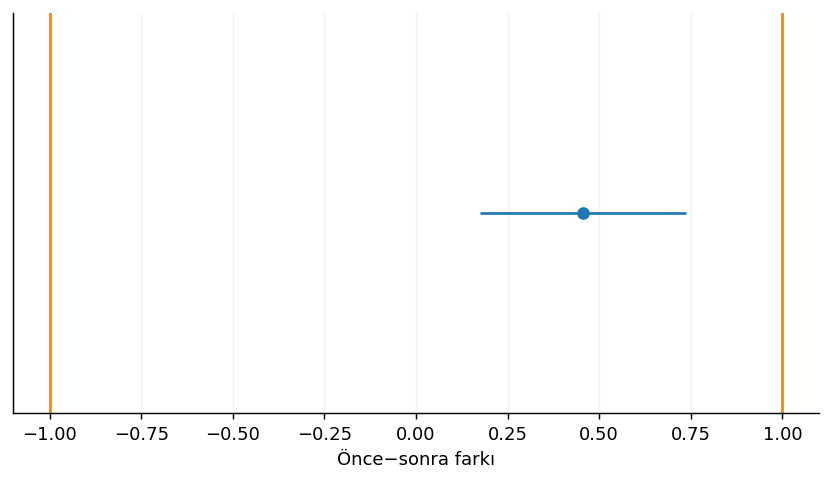

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

d=rng.normal(.1,1.2,50);delta=1.;se=stats.sem(d);df=len(d)-1
p_lower=stats.t.sf((d.mean()+delta)/se,df);p_upper=stats.t.cdf((d.mean()-delta)/se,df);ci=stats.t.interval(.90,df,loc=d.mean(),scale=se)
print({'fark':d.mean(),'TOST_p':max(p_lower,p_upper),'CI90':ci,'esdeger':bool(max(p_lower,p_upper)<.05),'asagi_kalmama_ust_sinir_p':p_upper})
plt.errorbar([d.mean()],[1],xerr=[[d.mean()-ci[0]],[ci[1]-d.mean()]],fmt='o');plt.axvline(-delta,c='tab:orange');plt.axvline(delta,c='tab:orange');plt.yticks([]);plt.xlabel('Önce−sonra farkı')